# Notebook 01 - Visualization and Quality Control

This notebook loads raw NIR and MIR data, infers working spectral ranges from the files found in `Data/`, validates input integrity, and exports QC summaries for downstream analysis.

## Quick Start (for new users)

1. Place one NIR CSV and one MIR CSV inside `Data/`.
2. If your files have different names, leave the filename fields empty and let the notebook auto-detect them.
3. Run all cells in order.
4. Confirm outputs in `Outputs/pipeline/`: `01_nir_raw_summary.csv`, `01_mir_raw_summary.csv`, `01_input_qc.json`, and `01_expected_ranges_inferred.csv`.
5. If a validation fails, follow the actionable error message before continuing to the next notebook.

## Theoretical Framework

### Data-First Configuration

This notebook derives working spectral ranges from the actual input files found in Data/ and stores them as Outputs/pipeline/01_expected_ranges_inferred.csv. This approach supports heterogeneous user datasets while keeping inference traceable and reproducible. Methodological overrides remain available through Reference/parameters.yaml.

Reference paths used:
- parameters.yaml -> preprocessing hyperparameters (smoothing, normalization, outlier detection)
- data_dictionary.yaml -> minimum required columns per domain
- 01_expected_ranges_inferred.csv -> inferred spectral ranges derived from the user's actual NIR/MIR files

Any methodological change must be applied first in the Reference/ files or the notebook user configuration, not by editing generated outputs.

### Automated Environment Bootstrap

A first-time user can place raw CSV files in Data/ and run the notebook directly. The next cell checks whether runtime dependencies are available in the active Python interpreter and installs any missing package automatically. This preserves accessibility for non-programmers while maintaining reproducibility in the selected environment.

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

RUNTIME_PACKAGES = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'pyyaml': 'yaml',
    'scipy': 'scipy',
    'scikit-learn': 'sklearn',
}

missing_packages = [pkg_name for pkg_name, module_name in RUNTIME_PACKAGES.items() if importlib.util.find_spec(module_name) is None]
if missing_packages:
    print('Missing dependencies detected in the active Python environment:')
    for package_name in missing_packages:
        print(f'  - {package_name}')
    print('Installing missing packages with pip...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--upgrade', 'pip'])
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing_packages])
    print('Dependency installation completed. Restart the kernel if the notebook asks for it.')
else:
    print('All runtime dependencies are already available in the active Python environment.')

if '.venv' not in str(sys.executable).lower():
    print('Warning: the active interpreter is not inside .venv. For a clean local run, select the project virtual environment.')


All runtime dependencies are already available in the active Python environment.


In [2]:
from pathlib import Path
import sys
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name.lower() == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from spectral_pipeline_utils import (
    get_spectral_columns,
    read_csv_auto,
    infer_domain_rules_from_wavelengths,
    expected_ranges_frame,
    validate_axis,
    fill_nans_matrix,
    run_stamp,
    write_json,
)

# User configuration: edit only this block when using a new dataset
NIR_FILENAME = ''  # Leave blank to auto-detect a NIR CSV in Data/
MIR_FILENAME = ''  # Leave blank to auto-detect a MIR CSV in Data/
OUTPUT_SUBFOLDER = 'pipeline'
AUTO_DETECT_INPUT_FILES = True

REFERENCE_DIR = ROOT / 'Reference'
DATA_DIR = ROOT / 'Data'
OUTPUT_DIR = ROOT / 'Outputs' / OUTPUT_SUBFOLDER
FIG_DIR = OUTPUT_DIR / 'Figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

PARAMS_PATH = REFERENCE_DIR / 'parameters.yaml'
DICT_PATH = REFERENCE_DIR / 'data_dictionary.yaml'
NIR_PATH = DATA_DIR / NIR_FILENAME if NIR_FILENAME else DATA_DIR / 'Atributos_VIS.NIR_SP.csv'
MIR_PATH = DATA_DIR / MIR_FILENAME if MIR_FILENAME else DATA_DIR / 'Atributos_MIR_SP.csv'
EXPECTED_RANGES_INFERRED_PATH = OUTPUT_DIR / '01_expected_ranges_inferred.csv'


def pick_input_file(preferred_name: str, domain_label: str) -> Path:
    if preferred_name:
        preferred_path = DATA_DIR / preferred_name
        if preferred_path.exists():
            return preferred_path
        if not AUTO_DETECT_INPUT_FILES:
            return preferred_path
        print(f'Configured {domain_label} file not found: {preferred_path.name}. Trying auto-detection in Data/.')

    candidates = sorted(DATA_DIR.glob('*.csv'))
    if not candidates:
        raise FileNotFoundError(f'No CSV files were found in {DATA_DIR}. Add one {domain_label} file and rerun.')

    keywords = {
        'nir': ('nir', 'vnir', 'visnir', 'vis', 'spectro'),
        'mir': ('mir', 'ftir', 'drift', 'mid'),
    }.get(domain_label.lower(), (domain_label.lower(),))

    matches = [path for path in candidates if any(keyword in path.name.lower() for keyword in keywords)]
    if len(matches) == 1:
        print(f'Auto-detected {domain_label.upper()} input file: {matches[0].name}')
        return matches[0]
    if len(matches) > 1:
        print(f'Multiple {domain_label.upper()} candidates found. Using first alphabetical match: {matches[0].name}')
        return matches[0]
    if len(candidates) == 1:
        print(f'Only one CSV found in Data/. Using it as {domain_label.upper()} input: {candidates[0].name}')
        return candidates[0]

    raise FileNotFoundError(
        f'Could not auto-detect a unique {domain_label} input file in {DATA_DIR}. '
        'Please leave the filename blank only if the file name contains a clear domain keyword, or set the filename explicitly in the user configuration.'
    )


NIR_PATH = pick_input_file(NIR_FILENAME, 'nir')
MIR_PATH = pick_input_file(MIR_FILENAME, 'mir')

required_paths = [
    ('parameters', PARAMS_PATH),
    ('data_dictionary', DICT_PATH),
    ('nir_input', NIR_PATH),
    ('mir_input', MIR_PATH),
]
missing = [f'{label}: {path}' for label, path in required_paths if not path.exists()]
if missing:
    raise FileNotFoundError(
        'Missing required files. Check paths and file names in User Configuration:\n' + '\n'.join(missing)
    )

with PARAMS_PATH.open('r', encoding='utf-8') as f:
    params = yaml.safe_load(f) or {}
with DICT_PATH.open('r', encoding='utf-8') as f:
    data_dict = yaml.safe_load(f) or {}

print('User configuration loaded successfully:')
print(f'  NIR input: {NIR_PATH}')
print(f'  MIR input: {MIR_PATH}')
print(f'  Output folder: {OUTPUT_DIR}')
print('  Spectral ranges will be inferred from the loaded data and saved to 01_expected_ranges_inferred.csv')

Auto-detected NIR input file: Atributos_VIS.NIR_SP.csv
Auto-detected MIR input file: Atributos_MIR_SP.csv
User configuration loaded successfully:
  NIR input: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Data\Atributos_VIS.NIR_SP.csv
  MIR input: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Data\Atributos_MIR_SP.csv
  Output folder: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline
  Spectral ranges will be inferred from the loaded data and saved to 01_expected_ranges_inferred.csv


## Input Preflight — User Data Validation

Before loading the full dataset, this check inspects each input file (NIR/MIR) to detect common formatting and integrity issues.

### What this preflight validates

- Delimiter consistency (comma, semicolon, tab)
- Decimal separator patterns in spectral values
- Presence of spectral columns in numeric wavelength/wavenumber format
- Potential one-column parse errors due to wrong delimiter
- Negative spectral values (treated as critical experimental errors)

If critical issues are found, execution stops with a clear action list so the files can be corrected before continuing.

In [3]:
import csv
import re


def _read_text_preview(path: Path, max_lines: int = 60) -> tuple[str, str]:
    last_err = None
    for enc in ('utf-8', 'latin1', 'cp1252'):
        try:
            with path.open('r', encoding=enc, errors='strict') as f:
                lines = []
                for _ in range(max_lines):
                    line = f.readline()
                    if not line:
                        break
                    lines.append(line)
            return ''.join(lines), enc
        except Exception as e:  # noqa: BLE001
            last_err = e
    raise RuntimeError(f'Could not read text preview for {path}: {last_err}')


def _guess_delimiter(preview: str) -> str:
    try:
        dialect = csv.Sniffer().sniff(preview, delimiters=',;\t|')
        return dialect.delimiter
    except Exception:  # noqa: BLE001
        counts = {
            ',': preview.count(','),
            ';': preview.count(';'),
            '\t': preview.count('\t'),
            '|': preview.count('|'),
        }
        return max(counts, key=counts.get)


def _to_float_header(col_name: str) -> float:
    txt = str(col_name).strip().replace('"', '')
    try:
        return float(txt)
    except ValueError:
        return np.nan


def _collect_numeric_tokens(series: pd.Series, max_tokens: int = 300) -> list[str]:
    tokens = []
    for val in series.dropna().astype(str).tolist():
        s = val.strip()
        if not s:
            continue
        if re.match(r'^[-+]?\d+(?:[\.,]\d+)?$', s):
            tokens.append(s)
        if len(tokens) >= max_tokens:
            break
    return tokens


def preflight_csv_spectral_input(path: Path, domain_label: str) -> dict:
    preview, enc = _read_text_preview(path)
    delim = _guess_delimiter(preview)

    df_preview = pd.read_csv(path, sep=delim, encoding=enc, nrows=60, dtype=str, low_memory=False)
    n_cols = int(df_preview.shape[1])

    wl_map = {c: _to_float_header(c) for c in df_preview.columns}
    spectral_cols = [c for c, v in wl_map.items() if np.isfinite(v)]

    token_pool = []
    for c in spectral_cols[:20]:
        token_pool.extend(_collect_numeric_tokens(df_preview[c]))
        if len(token_pool) >= 300:
            break

    comma_decimal = sum(bool(re.match(r'^[-+]?\d+,\d+$', t)) for t in token_pool)
    dot_decimal = sum(bool(re.match(r'^[-+]?\d+\.\d+$', t)) for t in token_pool)

    critical = []
    warnings = []

    if n_cols <= 1:
        critical.append(
            'File was parsed with a single column. This usually means a wrong delimiter or corrupted CSV structure.'
        )

    if len(spectral_cols) == 0:
        critical.append(
            'No spectral columns were detected from headers. Expected numeric names such as 450, 451, 452 or 4000, 3998.'
        )

    if delim != ',':
        warnings.append(f"Detected delimiter '{delim}'. Ensure this is intentional and consistent in all rows.")

    if comma_decimal > 0 and dot_decimal == 0:
        warnings.append(
            'Detected decimal comma values (for example 0,123). The pipeline expects decimal point values (for example 0.123).'
        )
    elif comma_decimal > 0 and dot_decimal > 0:
        critical.append(
            'Mixed decimal separators were detected (comma and point). Normalize numeric format before running the pipeline.'
        )

    # Attempt numeric conversion and hard-stop on negative spectral values
    negative_count = 0
    checked_values = 0
    if spectral_cols:
        numeric_block = df_preview[spectral_cols].replace(',', '.', regex=True)
        numeric_block = numeric_block.apply(pd.to_numeric, errors='coerce')
        arr = numeric_block.to_numpy(dtype=float)
        finite_mask = np.isfinite(arr)
        checked_values = int(np.sum(finite_mask))
        if checked_values > 0:
            negative_count = int(np.sum(arr[finite_mask] < 0))
            if negative_count > 0:
                critical.append(
                    f'Negative spectral values found ({negative_count} of {checked_values} checked values). This indicates experimental or export errors and invalidates the dataset.'
                )

    return {
        'domain': domain_label,
        'path': str(path),
        'encoding': enc,
        'delimiter': delim,
        'n_columns_preview': n_cols,
        'spectral_columns_detected': int(len(spectral_cols)),
        'decimal_tokens_comma': int(comma_decimal),
        'decimal_tokens_point': int(dot_decimal),
        'negative_values_preview': int(negative_count),
        'critical': critical,
        'warnings': warnings,
    }


preflight_results = [
    preflight_csv_spectral_input(NIR_PATH, 'NIR'),
    preflight_csv_spectral_input(MIR_PATH, 'MIR'),
]

all_critical = []
for result in preflight_results:
    print('-' * 88)
    print(f"[Preflight:{result['domain']}] {result['path']}")
    print(
        f"encoding={result['encoding']} | delimiter='{result['delimiter']}' | "
        f"columns={result['n_columns_preview']} | spectral_cols={result['spectral_columns_detected']}"
    )
    if result['warnings']:
        for msg in result['warnings']:
            print(f'WARNING: {msg}')
    if result['critical']:
        for msg in result['critical']:
            print(f'CRITICAL: {msg}')
            all_critical.append(f"{result['domain']}: {msg}")

print('-' * 88)
if all_critical:
    raise ValueError('Input preflight failed. Fix the following issues before continuing:\n- ' + '\n- '.join(all_critical))

print('Preflight checks passed. Input files are ready for Stage 01 processing.')

----------------------------------------------------------------------------------------
[Preflight:NIR] C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Data\Atributos_VIS.NIR_SP.csv
encoding=utf-8 | delimiter=',' | columns=2172 | spectral_cols=2151
----------------------------------------------------------------------------------------
[Preflight:MIR] C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Data\Atributos_MIR_SP.csv
encoding=utf-8 | delimiter=',' | columns=702 | spectral_cols=681
----------------------------------------------------------------------------------------
Preflight checks passed. Input files are ready for Stage 01 processing.


## Block 1 — Data Loading and Spectral Range Validation

### Spectral Domains: NIR and MIR

Soil data are captured in two complementary domains:

| Domain | Range | Unit | Characteristics |
|---------|-------|------|-----------------|
| Vis-NIR-SWIR | 350-2500 nm | nm | Electronic transitions (Fe, OM); combination vibrations (water, clays) |
| MIR | 400-4000 cm-1 | cm-1 | Fundamental molecular vibrations; higher analytical resolution |

According to Dematte et al. (2020) "Avaliacao dos solos do estado do Maranhao", ASD FieldSpec operates in the 350-2500 nm range with approximately 3 nm resolution in the visible region and approximately 10 nm in SWIR. MIR is acquired by diffuse reflectance (DRIFT) with 2 cm-1 resolution in the 400-4000 cm-1 range.

According to Dematte et al. (2022) "Fundamentos do sensoriamento espectral", the soil spectrum is a cumulative property of all its constituents (organic matter, Fe/Al oxides, clay minerals, quartz, residual water), with the spectral signature representing the integrated expression of these interactions.

### Full-Range Raw Spectral View

Stage 01 is dedicated to initial exploration and quality control. Therefore, spectra are visualized and summarized across the complete observed wavelength and wavenumber ranges, without preprocessing cuts.

This raw full-range view is important to:
- preserve transparency of the original measurements,
- detect broad instrumental or acquisition anomalies,
- provide a consistent baseline before preprocessing decisions in Stage 02.

In [4]:
params = params if 'params' in globals() else {}
data_dict = data_dict if 'data_dict' in globals() else {}

df_nir, enc_nir = read_csv_auto(NIR_PATH)
df_mir, enc_mir = read_csv_auto(MIR_PATH)

meta_nir_cols, nir_spec_cols, nir_wl = get_spectral_columns(df_nir)
meta_mir_cols, mir_spec_cols, mir_wl = get_spectral_columns(df_mir)

if len(nir_spec_cols) == 0:
    raise ValueError(
        'No NIR spectral columns were detected. Ensure spectral columns are numeric wavelength names (for example: 450, 451, 452).'
    )
if len(mir_spec_cols) == 0:
    raise ValueError(
        'No MIR spectral columns were detected. Ensure spectral columns are numeric wavenumber names (for example: 4000, 3998, 3996).'
    )

nir_rules = infer_domain_rules_from_wavelengths(nir_wl, 'nir')
mir_rules = infer_domain_rules_from_wavelengths(mir_wl, 'mir')
expected_ranges_frame([nir_rules, mir_rules]).to_csv(EXPECTED_RANGES_INFERRED_PATH, index=False)

nir_obs_min, nir_obs_max = validate_axis(nir_wl, nir_rules, 'NIR')
mir_obs_min, mir_obs_max = validate_axis(mir_wl, mir_rules, 'MIR')

nir_X = df_nir[nir_spec_cols].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)
mir_X = df_mir[mir_spec_cols].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)


def _negative_examples(X: np.ndarray, row_labels, spectral_cols: list[str], max_examples: int = 12):
    finite = np.isfinite(X)
    neg_mask = finite & (X < 0)
    neg_pos = np.argwhere(neg_mask)
    examples = []
    for r, c in neg_pos[:max_examples]:
        examples.append({
            'row_index': int(row_labels[r]),
            'spectral_column': str(spectral_cols[c]),
            'value': float(X[r, c]),
        })
    return int(neg_pos.shape[0]), examples


# Check for negative spectral values: warn but continue (non-blocking)
nir_neg_count, nir_neg_examples = _negative_examples(nir_X, df_nir.index.to_numpy(), nir_spec_cols)
mir_neg_count, mir_neg_examples = _negative_examples(mir_X, df_mir.index.to_numpy(), mir_spec_cols)

if nir_neg_count > 0 or mir_neg_count > 0:
    # Build and export diagnostic report
    def _build_negative_report(df, spectral_cols, domain):
        X = df[spectral_cols].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)
        finite = np.isfinite(X)
        neg_mask = finite & (X < 0)
        neg_pos = np.argwhere(neg_mask)
        if neg_pos.size == 0:
            return pd.DataFrame(columns=['domain', 'row_index', 'spectral_column', 'value'])
        rows = []
        row_labels = df.index.to_numpy()
        for r, c in neg_pos:
            rows.append({
                'domain': domain,
                'row_index': int(row_labels[r]),
                'spectral_column': str(spectral_cols[c]),
                'value': float(X[r, c]),
            })
        return pd.DataFrame(rows)

    nir_neg_df = _build_negative_report(df_nir, nir_spec_cols, 'NIR')
    mir_neg_df = _build_negative_report(df_mir, mir_spec_cols, 'MIR')
    neg_report_all = pd.concat([nir_neg_df, mir_neg_df], ignore_index=True)
    out_neg_csv = OUTPUT_DIR / '01_negative_values_report.csv'
    neg_report_all.to_csv(out_neg_csv, index=False)

    # Print prominent warning
    print('\n' + '=' * 88)
    print('WARNING: NEGATIVE SPECTRAL VALUES DETECTED')
    print('=' * 88)
    print(f'Total negatives found: {len(neg_report_all)}')
    print(f'  - NIR: {nir_neg_count}')
    print(f'  - MIR: {mir_neg_count}')
    print('\nDiagnostic report exported to:')
    print(f'  {out_neg_csv}')
    print('\nExamples (row_index | spectral_column | value):')
    for ex in list(nir_neg_examples + mir_neg_examples)[:12]:
        print(f"  - {ex['row_index']} | {ex['spectral_column']} | {ex['value']:.6g}")
    print('\nRecommendation: Review instrument baseline/export settings.')
    print('Pipeline continues, but consider regenerating the input CSV files.')
    print('=' * 88 + '\n')

nir_X = fill_nans_matrix(nir_X)
mir_X = fill_nans_matrix(mir_X)

nir_wl_raw = nir_wl.copy()
nir_X_raw = nir_X.copy()

# Stage 01 keeps full raw spectral range (no trimming)
nir_mean, nir_std = np.nanmean(nir_X, axis=0), np.nanstd(nir_X, axis=0)
mir_mean, mir_std = np.nanmean(mir_X, axis=0), np.nanstd(mir_X, axis=0)

print(f'NIR: {df_nir.shape} | bands_raw={len(nir_wl_raw)} | bands_used={len(nir_wl)} | encoding={enc_nir}')
print(f'MIR: {df_mir.shape} | bands={len(mir_wl)} | encoding={enc_mir}')
print(f'Input schema check: NIR metadata cols={len(meta_nir_cols)}, NIR spectral cols={len(nir_spec_cols)}')
print(f'Input schema check: MIR metadata cols={len(meta_mir_cols)}, MIR spectral cols={len(mir_spec_cols)}')
print(f'Inferred ranges saved to: {EXPECTED_RANGES_INFERRED_PATH}')
print('Stage 01 uses full raw spectral range without technical trim.')

NIR: (6120, 2172) | bands_raw=2151 | bands_used=2151 | encoding=utf-8
MIR: (616, 702) | bands=681 | encoding=utf-8
Input schema check: NIR metadata cols=21, NIR spectral cols=2151
Input schema check: MIR metadata cols=21, MIR spectral cols=681
Inferred ranges saved to: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\01_expected_ranges_inferred.csv
Stage 01 uses full raw spectral range without technical trim.


In [5]:
# Optional: regenerate full negative-value diagnostics manually
#
# In normal execution order, Cell 8 already exports 01_negative_values_report.csv
# whenever negatives are detected. Use this cell only if you need to re-export
# the report after changing inputs or after a kernel reset.
required = ['df_nir', 'df_mir', 'nir_spec_cols', 'mir_spec_cols']
if not all(v in globals() for v in required):
    raise RuntimeError('Missing required variables. Execute Cell 7 first.')

out_neg_csv = OUTPUT_DIR / '01_negative_values_report.csv'
if out_neg_csv.exists():
    print(f'Note: existing report found at {out_neg_csv}. It will be overwritten by this optional export.')


def _build_negative_report(df: pd.DataFrame, spectral_cols: list[str], domain: str) -> pd.DataFrame:
    X = df[spectral_cols].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)
    finite = np.isfinite(X)
    neg_mask = finite & (X < 0)
    neg_pos = np.argwhere(neg_mask)

    if neg_pos.size == 0:
        return pd.DataFrame(columns=['domain', 'row_index', 'spectral_column', 'value'])

    rows = []
    row_labels = df.index.to_numpy()
    for r, c in neg_pos:
        rows.append({
            'domain': domain,
            'row_index': int(row_labels[r]),
            'spectral_column': str(spectral_cols[c]),
            'value': float(X[r, c]),
        })
    return pd.DataFrame(rows)


nir_neg_df = _build_negative_report(df_nir, nir_spec_cols, 'NIR')
mir_neg_df = _build_negative_report(df_mir, mir_spec_cols, 'MIR')
neg_report = pd.concat([nir_neg_df, mir_neg_df], ignore_index=True)

neg_report.to_csv(out_neg_csv, index=False)

print(f'Negative diagnostics exported: {out_neg_csv}')
print(f'Total negatives: {len(neg_report)}')
if len(nir_neg_df) > 0:
    print(f'NIR negatives: {len(nir_neg_df)}')
if len(mir_neg_df) > 0:
    print(f'MIR negatives: {len(mir_neg_df)}')

if len(neg_report) > 0:
    display(neg_report.head(20))

Note: existing report found at C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\01_negative_values_report.csv. It will be overwritten by this optional export.
Negative diagnostics exported: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\01_negative_values_report.csv
Total negatives: 0


## Block 2 — Raw QC Visualization

### Visual Inspection: Mean +/- 1 SD

Representing the spectral mean with a band of +/-1 standard deviation allows detection of:
- registration problems: individual spectra far from the mean (outlier precursors),
- discontinuities: abrupt jumps at specific wavelengths caused by detector changes or acquisition artifacts,
- signal versus noise behavior by spectral zone.

This type of visual QC is implicit in the workflow described by Dematte et al. (2022) as a first step for spectral quality assessment.

### Full-Range Raw Spectral View

Each domain is first inspected using the complete raw spectral matrix (no trimming, no smoothing, no derivatives). This preserves transparency of the measured signal before any technical preprocessing in Stage 02.

### Why Stage 01 remains raw-only

Stage 01 is restricted to quality control and traceability of original measurements. Technical trim and Savitzky-Golay transformations (SG0/SG1/SG2) are part of Stage 02 preprocessing.

Madeira Netto (2001), "Comportamento espectral dos solos", describes how characteristic absorption bands of clays (kaolinite, illite, smectite), iron oxides, and organic matter generate features in spectral curves. In this workflow, derivative-based enhancement is intentionally deferred to Stage 02.

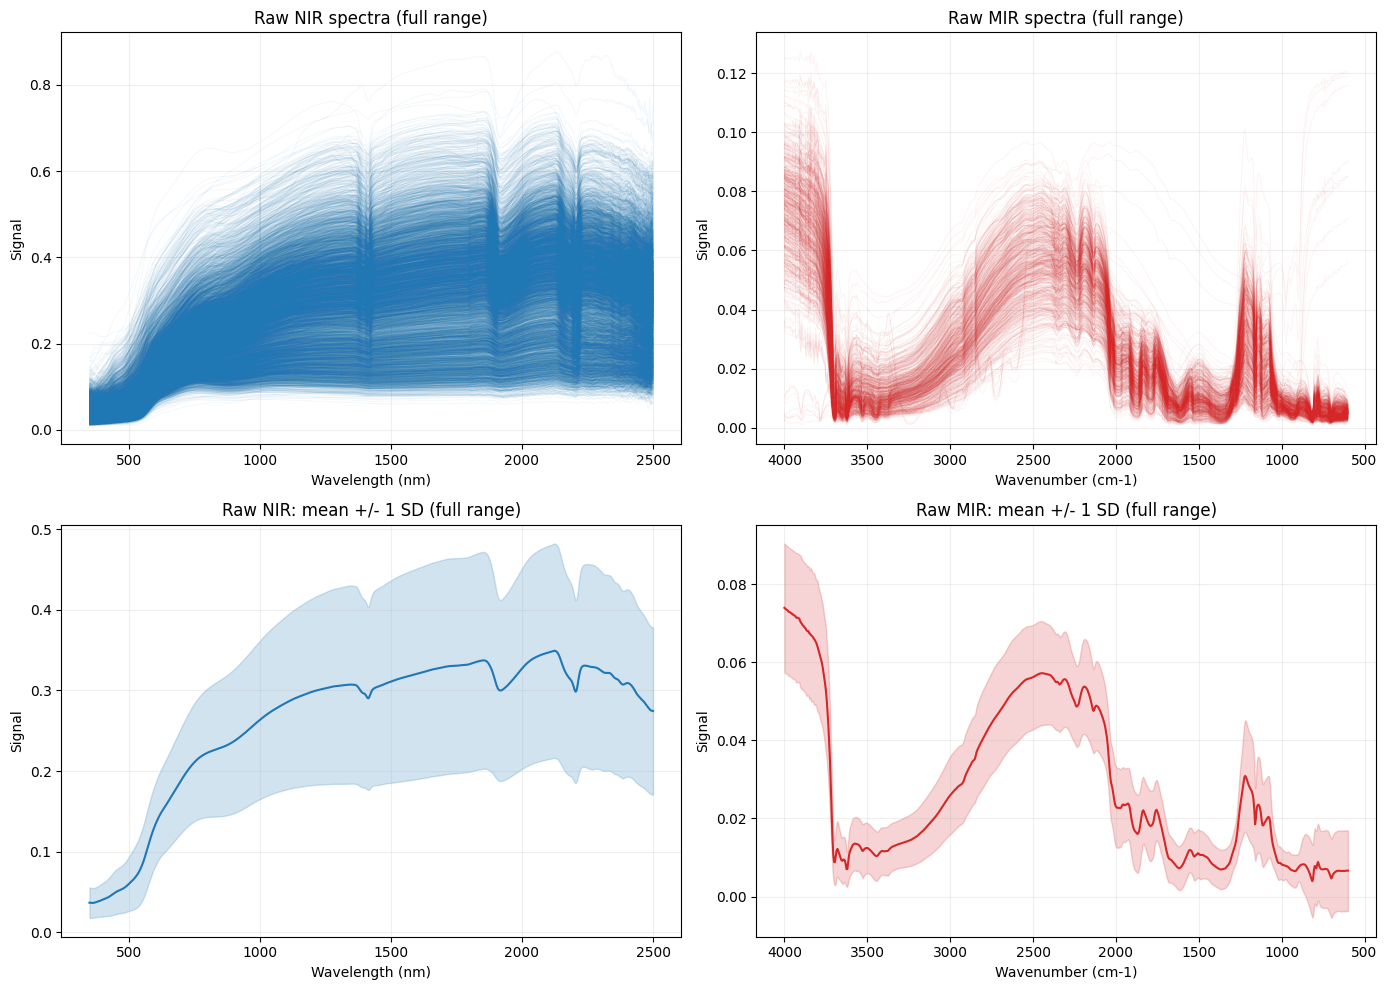

Figure saved: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\Figures\01_visual_qc_summary.png


In [6]:
# Defensive fallback: allows executing this cell even if kernel was restarted
import numpy as np
import matplotlib.pyplot as plt

required_vars = [
    'nir_wl_raw', 'nir_X_raw', 'nir_wl', 'nir_mean', 'nir_std',
    'mir_wl', 'mir_X', 'mir_mean', 'mir_std',
    'FIG_DIR',
]

if not all(v in globals() for v in required_vars):
    # Recalculate visualization variables from stage 01 loaded data
    if not all(v in globals() for v in ['df_nir', 'df_mir', 'nir_spec_cols', 'mir_spec_cols', 'nir_wl', 'mir_wl']):
        raise RuntimeError(
            'Missing variables for plotting. Execute cell 4 first, then cell 8 of this notebook.'
        )

    nir_X = df_nir[nir_spec_cols].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)
    mir_X = df_mir[mir_spec_cols].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float)
    nir_X = fill_nans_matrix(nir_X)
    mir_X = fill_nans_matrix(mir_X)

    nir_wl_raw = nir_wl.copy()
    nir_X_raw = nir_X.copy()

    nir_mean, nir_std = np.nanmean(nir_X, axis=0), np.nanstd(nir_X, axis=0)
    mir_mean, mir_std = np.nanmean(mir_X, axis=0), np.nanstd(mir_X, axis=0)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(nir_wl_raw, nir_X_raw.T, color='tab:blue', alpha=0.06, lw=0.6)
axes[0, 0].set_title('Raw NIR spectra (full range)')
axes[0, 0].set_xlabel('Wavelength (nm)')
axes[0, 0].set_ylabel('Signal')
axes[0, 0].grid(alpha=0.2)

axes[0, 1].plot(mir_wl, mir_X.T, color='tab:red', alpha=0.06, lw=0.6)
axes[0, 1].set_title('Raw MIR spectra (full range)')
axes[0, 1].set_xlabel('Wavenumber (cm-1)')
axes[0, 1].set_ylabel('Signal')
axes[0, 1].invert_xaxis()
axes[0, 1].grid(alpha=0.2)

axes[1, 0].plot(nir_wl, nir_mean, color='tab:blue', lw=1.5)
axes[1, 0].fill_between(nir_wl, nir_mean - nir_std, nir_mean + nir_std, color='tab:blue', alpha=0.2)
axes[1, 0].set_title('Raw NIR: mean +/- 1 SD (full range)')
axes[1, 0].set_xlabel('Wavelength (nm)')
axes[1, 0].set_ylabel('Signal')
axes[1, 0].grid(alpha=0.2)

axes[1, 1].plot(mir_wl, mir_mean, color='tab:red', lw=1.5)
axes[1, 1].fill_between(mir_wl, mir_mean - mir_std, mir_mean + mir_std, color='tab:red', alpha=0.2)
axes[1, 1].set_title('Raw MIR: mean +/- 1 SD (full range)')
axes[1, 1].set_xlabel('Wavenumber (cm-1)')
axes[1, 1].invert_xaxis()
axes[1, 1].set_ylabel('Signal')
axes[1, 1].grid(alpha=0.2)

fig.tight_layout()
fig_path = FIG_DIR / '01_visual_qc_summary.png'
fig.savefig(fig_path, dpi=180)
plt.show()
print(f'Figure saved: {fig_path}')

## Block 3 — Artifact Export

### Why Are These Files Generated?

This notebook produces three output types with distinct and complementary roles:

---

#### 01_nir_raw_summary.csv and 01_mir_raw_summary.csv
What are they?
Single-row tables with descriptive statistics of the raw dataset per domain: dimensions (n_samples x n_features), observed ranges, number of spectral bands used, and source file encoding.

What are they for?
- Detect whether a new data batch differs from expected spectral behavior.
- Serve as the dataset presentation card for methodological audits.
- Establish contract checks for the following notebook, which verifies 01_input_qc.json before execution.

---

#### 01_input_qc.json
What is it?
A traceability record with timestamp, absolute paths of all inputs, observed ranges, and paths of all outputs. It is the execution seal of this notebook.

What is it for?
- Required by the following notebook as proof that QC was executed correctly before preprocessing.
- Allows exact reconstruction of what data, parameters and reference version were used (auditability).
- pipeline_manifest.json (generated at workflow end) aggregates all notebook JSON files as full execution traces.

---

#### 01_visual_qc_summary.png
What is it?
A panel with four subplots: raw full-range NIR spectra, raw full-range MIR spectra, and mean +/- SD summaries for NIR and MIR.

What is it for?
Quick visual inspection before preprocessing. It helps detect anomalies that statistics alone do not capture (inverted scales, instrumental jumps, unusual signatures).

---

Together, these artifacts implement end-to-end traceability as proposed by Poppiel et al. (2022) and reiterated in the methodology of Wadoux et al. (2021), where each methodological decision must be documented and linked to the data that produced it.

In [7]:
nir_summary = pd.DataFrame([{
    'domain': 'nir',
    'n_samples': int(df_nir.shape[0]),
    'n_features_total': int(df_nir.shape[1]),
    'n_spectral_bands_raw': int(len(nir_wl_raw)),
    'n_spectral_bands_used': int(len(nir_wl)),
    'wl_min_observed_raw': float(nir_obs_min),
    'wl_max_observed_raw': float(nir_obs_max),
    'wl_min_used': float(np.nanmin(nir_wl)),
    'wl_max_used': float(np.nanmax(nir_wl)),
    'wl_min_expected': float(nir_rules['wl_min']),
    'wl_max_expected': float(nir_rules['wl_max']),
    'encoding': enc_nir,
}])

mir_summary = pd.DataFrame([{
    'domain': 'mir',
    'n_samples': int(df_mir.shape[0]),
    'n_features_total': int(df_mir.shape[1]),
    'n_spectral_bands': int(len(mir_wl)),
    'wl_min_observed': float(mir_obs_min),
    'wl_max_observed': float(mir_obs_max),
    'wl_min_expected': float(mir_rules['wl_min']),
    'wl_max_expected': float(mir_rules['wl_max']),
    'encoding': enc_mir,
}])

out_nir_summary = OUTPUT_DIR / '01_nir_raw_summary.csv'
out_mir_summary = OUTPUT_DIR / '01_mir_raw_summary.csv'
out_qc_json = OUTPUT_DIR / '01_input_qc.json'
out_checklist_json = OUTPUT_DIR / '01_input_checklist.json'
nir_summary.to_csv(out_nir_summary, index=False)
mir_summary.to_csv(out_mir_summary, index=False)

input_checklist = {
    'status': 'PASS',
    'checks': {
        'nir_file_exists': bool(NIR_PATH.exists()),
        'mir_file_exists': bool(MIR_PATH.exists()),
        'nir_spectral_columns_detected': int(len(nir_spec_cols)),
        'mir_spectral_columns_detected': int(len(mir_spec_cols)),
        'nir_range_observed': [float(nir_obs_min), float(nir_obs_max)],
        'mir_range_observed': [float(mir_obs_min), float(mir_obs_max)],
        'nir_range_expected': [float(nir_rules['wl_min']), float(nir_rules['wl_max'])],
        'mir_range_expected': [float(mir_rules['wl_min']), float(mir_rules['wl_max'])],
        'generated_expected_ranges_csv': str(EXPECTED_RANGES_INFERRED_PATH),
    },
}
write_json(out_checklist_json, input_checklist)

qc_payload = run_stamp('01_visualizacion_qc', {
    'inputs': {
        'nir': str(NIR_PATH),
        'mir': str(MIR_PATH),
        'parameters': str(PARAMS_PATH),
        'data_dictionary': str(DICT_PATH),
    },
    'spectral_ranges': {
        'generated_from_input_data': str(EXPECTED_RANGES_INFERRED_PATH),
        'nir': nir_rules,
        'mir': mir_rules,
    },
    'stage_01_policy': {
        'full_range_visualization': True,
        'preprocessing_applied': False,
    },
    'outputs': {
        'nir_summary_csv': str(out_nir_summary),
        'mir_summary_csv': str(out_mir_summary),
        'qc_json': str(out_qc_json),
        'input_checklist_json': str(out_checklist_json),
        'inferred_ranges_csv': str(EXPECTED_RANGES_INFERRED_PATH),
        'figure': str(fig_path),
    },
})
write_json(out_qc_json, qc_payload)

print(f'Saved: {out_nir_summary}')
print(f'Saved: {out_mir_summary}')
print(f'Saved: {out_qc_json}')
print(f'Saved: {out_checklist_json}')
print(f'Saved: {EXPECTED_RANGES_INFERRED_PATH}')

Saved: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\01_nir_raw_summary.csv
Saved: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\01_mir_raw_summary.csv
Saved: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\01_input_qc.json
Saved: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\01_input_checklist.json
Saved: C:\Users\DANIEL\Desktop\GeoCiS_Spectroscopy\Outputs\pipeline\01_expected_ranges_inferred.csv
